# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024160042          # <-- your full roll number
NAME = "Dhiren Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [9]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160042   Name: Dhiren Kumar   Fingerprint: E2F54452   Tickets: 14

Ticket_ID                                                                             Ticket_Text
      T01                                             I can't login and I didn't change anything.
      T02                     The projector crashes while opening. The same problem occurs again.
      T03                                                    Python 3.12 was installed yesterday.
      T04                                 The projector keeps disconnecting. It worked yesterday.
      T05                 I was locked out of the laptop on my laptop. Is there another solution?
      T06                                   The laptop crashes while opening. Can you check this?
      T07                                                    Email me at helpdesk@university.edu.
      T08         Python stopped responding while uploading the file. I have tried several times!
      T09                         

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [10]:
import pandas as pd
import nltk
import string
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

roll_no = 1024160042

df, focus, fingerprint = generate_dataset(roll_no)

tickets = df['Ticket_Text'].tolist()

print("Generated Dataset:")
display(df)

print("\nFocus Ticket IDs:", focus)

print("\nFingerprint:", fingerprint)

print("\nTotal Tickets:", len(tickets))

processed_tickets = []

for ticket in tickets:
    result = process_ticket(ticket)
    processed_tickets.append(result)

rows = []

for i, ticket in enumerate(tickets):

    sentences = sent_tokenize(ticket)
    tokens = word_tokenize(ticket)

    punctuation_tokens = [
        word for word in tokens
        if all(ch in string.punctuation for ch in word)
    ]

    stopword_tokens = [
        word for word in tokens
        if word.lower() in stop_words
    ]

    final_tokens = [
        word for word in tokens
        if word.lower() not in stop_words
        and word not in punctuation_tokens
    ]

    rows.append({
        'Ticket': i + 1,
        'Sentences': len(sentences),
        'Tokens': len(tokens),
        'Punctuation Tokens': len(punctuation_tokens),
        'Stopwords': len(stopword_tokens),
        'Unique Tokens': len(set(tokens)),
        'Final Tokens': len(final_tokens)
    })

df = pd.DataFrame(rows)

total = {
    'Ticket': 'TOTAL',
    'Sentences': df['Sentences'].sum(),
    'Tokens': df['Tokens'].sum(),
    'Punctuation Tokens': df['Punctuation Tokens'].sum(),
    'Stopwords': df['Stopwords'].sum(),
    'Unique Tokens': '-',
    'Final Tokens': df['Final Tokens'].sum()
}

df.loc[len(df)] = total

display(df)

selected_ticket = 1

text = tickets[selected_ticket - 1]
tokens = word_tokenize(text)

punctuation_tokens = [
    word for word in tokens
    if all(ch in string.punctuation for ch in word)
]

stopword_tokens = [
    word for word in tokens
    if word.lower() in stop_words
]

final_tokens = [
    word for word in tokens
    if word.lower() not in stop_words
    and word not in punctuation_tokens
]

print("Selected Ticket:", text)
print("\nActual Tokens:", tokens)
print("\nPunctuation Tokens:", punctuation_tokens)
print("\nStopwords:", stopword_tokens)
print("\nFinal Tokens:", final_tokens)

Generated Dataset:


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Ticket_ID,Ticket_Text
0,T01,I can't login and I didn't change anything.
1,T02,The projector crashes while opening. The same ...
2,T03,Python 3.12 was installed yesterday.
3,T04,The projector keeps disconnecting. It worked y...
4,T05,I was locked out of the laptop on my laptop. I...
5,T06,The laptop crashes while opening. Can you chec...
6,T07,Email me at helpdesk@university.edu.
7,T08,Python stopped responding while uploading the ...
8,T09,The password keeps disconnecting. I don't know...
9,T10,WiFi is showing an error when connected to cam...



Focus Ticket IDs: ['T13', 'T14']

Fingerprint: E2F54452

Total Tickets: 14


,Ticket,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,1,1,11,1,4,9,6
1,2,2,12,2,5,10,5
2,3,1,6,1,1,6,4
3,4,2,9,2,2,8,5
4,5,2,16,2,9,15,5
5,6,2,11,2,5,11,4
6,7,1,7,2,2,7,3
7,8,2,14,2,4,14,8
8,9,2,12,2,4,11,6
9,10,2,17,2,7,16,8


Selected Ticket: I can't login and I didn't change anything.

Actual Tokens: ['I', 'ca', "n't", 'login', 'and', 'I', 'did', "n't", 'change', 'anything', '.']

Punctuation Tokens: ['.']

Stopwords: ['I', 'and', 'I', 'did']

Final Tokens: ['ca', "n't", 'login', "n't", 'change', 'anything']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [11]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

for i, ticket in enumerate(tickets):

    print("\nTICKET", i + 1)

    long_words = re.findall(r'\b[A-Za-z]{6,}\b', ticket)

    numbers = re.findall(
        r'(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?![\w.])',
        ticket
    )

    capitalized = re.findall(r'\b[A-Z][a-zA-Z]*\b', ticket)

    vowel_words = re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', ticket)

    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized)
    print("Vowel words:", vowel_words)


email_pattern = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'

url_pattern = r'https?://[^\s<>"\']+|www\.[^\s<>"\']+'

phone_pattern = (
    r'(?<!\w)(?:\+?\d{1,3}[-.\s]?)?'
    r'(?:\(\d{2,4}\)|\d{2,4})[-.\s]?'
    r'\d{3,4}[-.\s]?\d{3,4}(?!\w)'
)

print("\nREGEX REPLACEMENT")

for ticket in tickets:

    result = re.sub(email_pattern, '<EMAIL>', ticket)
    result = re.sub(url_pattern, '<URL>', result)
    result = re.sub(phone_pattern, '<PHONE>', result)

    print(result)


print("\nTEST_LINES")

for line in TEST_LINES:

    result = re.sub(email_pattern, '<EMAIL>', line)
    result = re.sub(url_pattern, '<URL>', result)
    result = re.sub(phone_pattern, '<PHONE>', result)

    print("Original:", line)
    print("Replaced:", result)


TICKET 1
Long words: ['change', 'anything']
Numbers: []
Capitalized words: ['I', 'I']
Vowel words: ['I', 'and', 'I', 'anything']

TICKET 2
Long words: ['projector', 'crashes', 'opening', 'problem', 'occurs']
Numbers: []
Capitalized words: ['The', 'The']
Vowel words: ['opening', 'occurs', 'again']

TICKET 3
Long words: ['Python', 'installed', 'yesterday']
Numbers: ['3.12']
Capitalized words: ['Python']
Vowel words: ['installed']

TICKET 4
Long words: ['projector', 'disconnecting', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['The', 'It']
Vowel words: ['It']

TICKET 5
Long words: ['locked', 'laptop', 'laptop', 'another', 'solution']
Numbers: []
Capitalized words: ['I', 'Is']
Vowel words: ['I', 'out', 'of', 'on', 'Is', 'another']

TICKET 6
Long words: ['laptop', 'crashes', 'opening']
Numbers: []
Capitalized words: ['The', 'Can']
Vowel words: ['opening']

TICKET 7
Long words: ['helpdesk', 'university']
Numbers: []
Capitalized words: ['Email']
Vowel words: ['Email', 'at', 'univer

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r'https?://[^\s<>"\']+|'
    r'www\.[^\s<>"\']+|'
    r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|'
    r'\+?\d[\d\s().-]{7,}\d|'
    r'\d+(?:\.\d+)+|'
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"
    r'[A-Za-z]+(?:-[A-Za-z]+)+|'
    r'[A-Za-z]+|'
    r'\d+|'
    r'[^\w\s]'
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


print("CUSTOM TOKENIZER ON TEST_LINES")

for line in TEST_LINES:

    print("\nOriginal:", line)
    print("My Tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))


print("\nCUSTOM TOKENIZER ON TICKETS")

for i, ticket in enumerate(tickets):

    print("\nTicket", i + 1)
    print(my_tokenize(ticket))


print("\nTOKENIZER DIFFERENCES")

count = 0

for line in TEST_LINES:

    custom = my_tokenize(line)
    standard = word_tokenize(line)

    if custom != standard:

        print("\nText:", line)
        print("Custom:", custom)
        print("NLTK:", standard)

        count += 1

    if count == 5:
        break


print("\nDifferences displayed:", count)

CUSTOM TOKENIZER ON TEST_LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My Tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My Tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('omw-1.4')

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_words = sorted(set(
    word.lower()
    for ticket in tickets
    for word in word_tokenize(ticket)
    if word.isalpha() and word.lower() not in stop_words
))


ing_words = [w for w in unique_words if w.endswith('ing')]
ed_words = [w for w in unique_words if w.endswith('ed')]
ly_words = [w for w in unique_words if w.endswith('ly')]

if len(ing_words) >= 2:
    suffix = 'ing'
    examples = ing_words[:5]
elif len(ed_words) >= 2:
    suffix = 'ed'
    examples = ed_words[:5]
elif len(ly_words) >= 2:
    suffix = 'ly'
    examples = ly_words[:5]
else:
    suffix = 's'
    examples = [w for w in unique_words if w.endswith('s')][:5]

regexp = RegexpStemmer(suffix)

print("Selected suffix:", suffix)
print("Dataset examples:", examples)
print("Justification: This suffix occurs in multiple words in the dataset.")


def get_wordnet_pos(word):

    tag = pos_tag([word])[0][1]

    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'

    return 'n'


rows = []

for word in unique_words:

    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp.stem(word)

    pos = get_wordnet_pos(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    if len(set([p, l, r, lemma])) > 1:

        rows.append({
            'Original Word': word,
            'Porter Stemmer': p,
            'Lancaster Stemmer': l,
            'Regexp Stemmer': r,
            'WordNet Lemmatizer': lemma,
            'POS': pos
        })

stemming_df = pd.DataFrame(rows)

print("\nWords having different outputs:")
display(stemming_df)

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Selected suffix: ing
Dataset examples: ['anything', 'disconnecting', 'opening', 'responding', 'restarting']
Justification: This suffix occurs in multiple words in the dataset.

Words having different outputs:


,Original Word,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer,POS
0,another,anoth,anoth,another,another,n
1,anything,anyth,anyth,anyth,anything,n
2,campus,campu,camp,campus,campus,n
3,change,chang,chang,change,change,n
4,changed,chang,chang,changed,change,v
5,connected,connect,connect,connected,connect,v
6,crashes,crash,crash,crashes,crash,n
7,error,error,er,error,error,n
8,failed,fail,fail,failed,fail,v
9,file,file,fil,file,file,n


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,160,86,0.5375
1,S2,132,81,0.6136
2,S3,74,52,0.7027
3,S4,74,50,0.6757



TOP 10 WORDS IN S1


,Word,Frequency
0,.,20
1,the,11
2,i,6
3,yesterday,4
4,is,4
5,!,4
6,n't,3
7,while,3
8,again,3
9,python,3



TOP 10 WORDS IN S3


,Word,Frequency
0,yesterday,4
1,n't,3
2,python,3
3,worked,3
4,laptop,3
5,projector,2
6,crashes,2
7,opening,2
8,problem,2
9,occurs,2


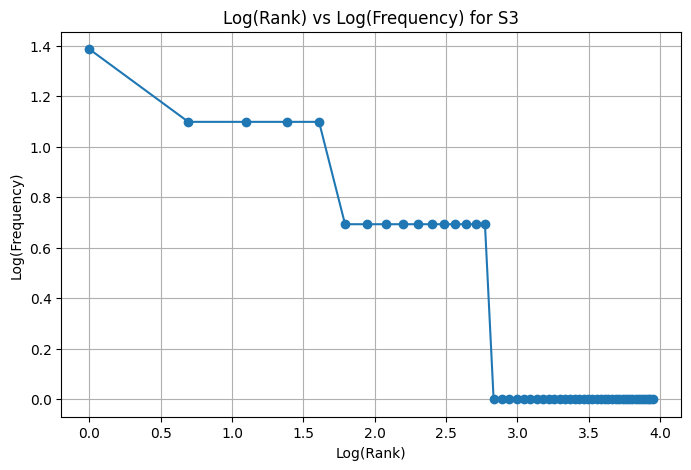


TOP 5 BIGRAMS IN S1
('.', 'the') : 5
('yesterday', '.') : 4
('.', 'i') : 4
('.', 'it') : 3
('it', 'worked') : 3

TOP 5 BIGRAMS IN S3
('worked', 'yesterday') : 3
('crashes', 'opening') : 2
('problem', 'occurs') : 2
('keeps', 'disconnecting') : 2
('python', 'stopped') : 2


In [14]:
# Your code
from collections import Counter
from nltk.util import bigrams
import math
import matplotlib.pyplot as plt


S1 = [
    word.lower()
    for ticket in tickets
    for word in word_tokenize(ticket)
]

S2 = [
    word for word in S1
    if not all(ch in string.punctuation for ch in word)
]

S3 = [
    word.lower()
    for ticket in tickets
    for word in word_tokenize(ticket)
    if word.lower() not in stop_words
    and not all(ch in string.punctuation for ch in word)
]

S4 = [porter.stem(word) for word in S3]

def calculate_statistics(tokens):

    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return total, unique, round(ttr, 4)


corpora = {
    'S1': S1,
    'S2': S2,
    'S3': S3,
    'S4': S4
}

rows = []

for name, corpus in corpora.items():

    total, unique, ttr = calculate_statistics(corpus)

    rows.append({
        'Corpus': name,
        'Total Tokens': total,
        'Unique Tokens': unique,
        'TTR': ttr
    })

display(pd.DataFrame(rows))


print("\nTOP 10 WORDS IN S1")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=['Word', 'Frequency']
))

print("\nTOP 10 WORDS IN S3")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=['Word', 'Frequency']
))


frequency = Counter(S3)
sorted_freq = sorted(frequency.values(), reverse=True)

ranks = range(1, len(sorted_freq) + 1)

log_ranks = [math.log(r) for r in ranks]
log_freq = [math.log(f) for f in sorted_freq]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_freq, marker='o')
plt.xlabel('Log(Rank)')
plt.ylabel('Log(Frequency)')
plt.title('Log(Rank) vs Log(Frequency) for S3')
plt.grid(True)
plt.show()


print("\nTOP 5 BIGRAMS IN S1")

for pair, count in Counter(bigrams(S1)).most_common(5):
    print(pair, ":", count)


print("\nTOP 5 BIGRAMS IN S3")

for pair, count in Counter(bigrams(S3)).most_common(5):
    print(pair, ":", count)

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*As we move from S1 to S4, preprocessing removes punctuation and other unwanted tokens. Stemming also converts related words into a common root form. For example, words like disconnecting and disconnected may become the same stem.

This generally reduces the number of unique tokens relative to the total number of tokens, so TTR tends to decrease.